# ЛР 1 - Результат поста относительно обычного уровня автора

Ростислав Манзюк, GitHub: grinchaus

Здесь сравниваю baseline, CatBoost с историей и метаданными, TF-IDF и смешивание моделей. В CatBoost также добавлены локальные эмбеддинги multilingual E5-small. Итоговый PDF лежит в `submission/`.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
assert (ROOT / "lab1_config.json").is_file(), "Открой notebook из корня репозитория"
DATA = ROOT / "data"
RESULTS = ROOT / "results" / "lab1"
config = json.loads((ROOT / "lab1_config.json").read_text())

def run(*args):
    subprocess.run([sys.executable, *map(str, args)], cwd=ROOT, check=True)

assert (DATA / "labels.csv").is_file(), "Нужен официальный распакованный датасет"
display(config)

{'depth': 6,
 'iterations': 2400,
 'text_c': 1.0,
 'threads': 8,
 'post_components': 64,
 'profile_components': 16,
 'embeddings': {'model': 'intfloat/multilingual-e5-small',
  'revision': '614241f622f53c4eeff9890bdc4f31cfecc418b3',
  'batch_size': 24}}

## Данные и разделение

Официальный test не меняю. Валидация выделена только из train по авторам, seed 42. Авторы между частями не пересекаются. Перед обучением проверяю, что все 89 018 меток воспроизводятся из постов штатной функцией.

In [2]:
run("-m", "kairos.label", "--data", DATA)
labels = pd.read_csv(DATA / "labels.csv")
train_authors = set(labels.loc[labels.split == "train", "author"])
test_authors = set(labels.loc[labels.split == "test", "author"])
assert not train_authors & test_authors
assert len(labels.loc[labels.split == "train"]) == 71395
assert len(labels.loc[labels.split == "test"]) == 17623
display(labels.groupby(["split", "class"]).size().unstack(fill_value=0))

posts:  12%|█▏        | 665/5433 [00:00<00:01, 3346.03file/s]

posts:  26%|██▌       | 1386/5433 [00:00<00:01, 3512.38file/s]

posts:  38%|███▊      | 2083/5433 [00:00<00:00, 3388.54file/s]

posts:  51%|█████     | 2758/5433 [00:00<00:00, 3094.06file/s]

posts:  63%|██████▎   | 3407/5433 [00:01<00:00, 3095.13file/s]

posts:  75%|███████▌  | 4085/5433 [00:01<00:00, 3210.89file/s]

posts:  87%|████████▋ | 4730/5433 [00:01<00:00, 3155.20file/s]

posts: 100%|██████████| 5433/5433 [00:01<00:00, 3263.44file/s]


cutoffs  low -0.549306 (split.json -0.549306)  high +1.157453 (split.json +1.157453)
labels.csv 89,018  recomputed 89,018  in both 89,018  agree 89,018
every label reproduces


class,above,below,typical
split,,,
test,3591,3541,10491
train,14278,14225,42892


## Обучение и воспроизведение

Параметры выбраны на валидации и зафиксированы в `submission/selection.json`. Веса encoder тоже закреплены на конкретной ревизии. Словари, заполнение пропусков, масштабирование, PCA и классификаторы обучаются на train. Все окна истории закрываются перед текущим постом.

`run_lab1.py` выполняет полный запуск. Если локальный запуск уже выполнен, ниже используются его результаты. В новом клоне репозитория модели будут обучены заново.

In [3]:
if not (RESULTS / "metrics.json").is_file() or not (RESULTS / "model.joblib").is_file():
    run("run_lab1.py", "--data", DATA)
else:
    print("Загружены результаты локального запуска. Для полного пересчёта: python run_lab1.py --data data")
metrics = json.loads((RESULTS / "metrics.json").read_text())
assert metrics["data_kind"] == "official-release"
assert metrics["train_posts"] == 71395 and metrics["test_posts"] == 17623
display(pd.DataFrame(metrics["validation"]).T)
display(pd.DataFrame({name: {key: value[key] for key in ["macro_f1", "qwk", "accuracy"]}
                      for name, value in metrics["test"].items()}).T)
print("Параметры смешивания:", metrics["selected_config"])
display(metrics["confidence_intervals"])

Загружены результаты локального запуска. Для полного пересчёта: python run_lab1.py --data data


,macro_f1,qwk,accuracy
official_baseline,0.5587,0.4876,0.5634
history_catboost,0.6385,0.5930,0.6474
text_and_metadata,0.6114,0.5517,0.6294
selected_blend,0.6662,0.6079,0.6982


,macro_f1,qwk,accuracy
official_baseline,0.5403,0.4603,0.5445
history_catboost,0.6255,0.5771,0.6349
text_and_metadata,0.5931,0.5319,0.6105
selected_blend,0.6535,0.5917,0.6871
always_typical,0.2488,0.0000,0.5953


Параметры смешивания: {'validation_macro_f1': 0.6662434780744835, 'tree_weight': [0.6, 1.0, 0.6], 'class_weights': [0.75, 1.0, 0.6]}


{'method': 'paired percentile bootstrap by author',
 'samples': 2000,
 'seed': 42,
 'authors': 824,
 'macro_f1_95ci': {'official_baseline': [0.5297, 0.5505],
  'history_catboost': [0.6159, 0.635],
  'text_and_metadata': [0.5828, 0.6038],
  'selected_blend': [0.644, 0.6631]},
 'selected_minus_baseline_95ci': [0.1042, 0.1223]}

## Ошибки и признаки

Смотрю не только общий macro-F1, но и ошибки между классами. Важности ниже относятся к CatBoost; они не доказывают причинный эффект отдельных признаков.

,precision,recall,f1-score,support
below,0.524775,0.577238,0.549758,3541.000000
typical,0.743536,0.740063,0.741795,10491.000000
above,0.699939,0.640490,0.668896,3591.000000
accuracy,0.687057,0.687057,0.687057,0.687057
macro avg,0.656083,0.652597,0.653483,17623.000000
weighted avg,0.690696,0.687057,0.688355,17623.000000


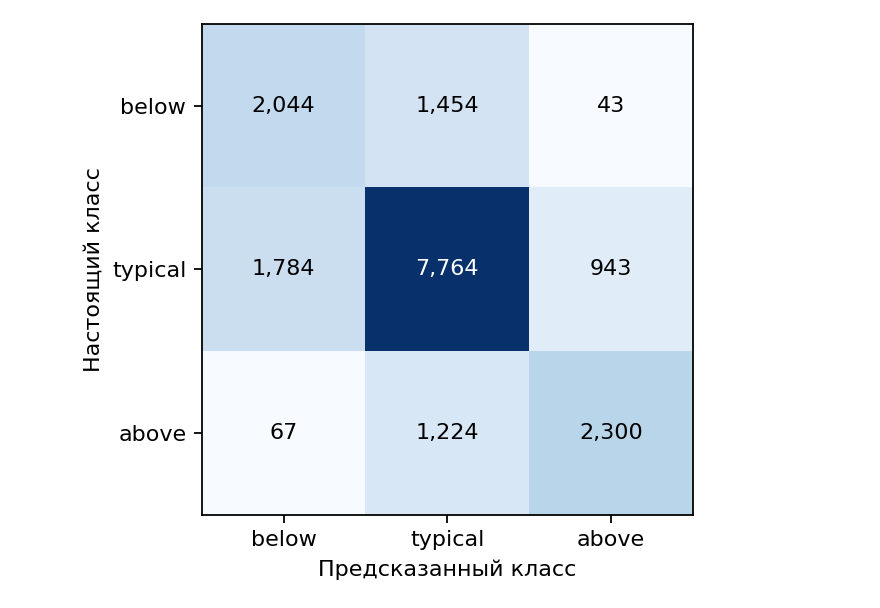

,Unnamed: 0,importance
0,content_type,5.870114
1,level,5.833833
2,e5_post_pc000,4.390238
3,is_reshare,3.788011
4,n_chars_relative20,2.694197
5,level_to_followers,2.356645
6,recent_level_delta5,1.960456
7,n_words_relative20,1.848750
8,e5_post_pc001,1.742230
9,recent_level_delta10,1.640951


In [4]:
display(pd.DataFrame(metrics["test"]["selected_blend"]["classification_report"]).T)
display(Image(filename=str(RESULTS / "confusion_matrix.png")))
display(pd.read_csv(RESULTS / "feature_importance.csv").head(20))

## Повторный inference и готовый комплект

Штатный evaluator проверяет покрытие всех test-постов. Затем отдельно загружаю сохранённую модель и проверяю, что все предсказания совпадают. PDF и CSV собираются только из измеренных результатов.

In [5]:
run("evaluate.py", "--data", DATA, "--predictions", RESULTS / "selected_blend.csv")
run("predict_lab1.py", "--data", DATA)
original = pd.read_csv(RESULTS / "selected_blend.csv")
repeated = pd.read_csv(RESULTS / "reproduced.csv")
pd.testing.assert_frame_equal(original, repeated)
run("make_report.py", "--results", RESULTS)
run("tools/prepare_submission.py", "--data", DATA, "--results", RESULTS)
print("Все предсказания воспроизвелись. Комплект для сдачи:")
for path in sorted((ROOT / "submission").iterdir()):
    print(path.name)

test: 17,623 posts
  macro-F1  0.6535   (primary)
  QWK       0.5917
  accuracy  0.6871
  F1 by class  below 0.5498  typical 0.7418  above 0.6689
  confusion, rows = truth below / typical / above:
      2,044   1,454      43
      1,784   7,764     943
         67   1,224   2,300


results/lab1/reproduced.csv


submission/Lab1_Rostislav_Manzyuk.pdf


Validated submission: {'macro_f1': 0.6535, 'qwk': 0.5917, 'accuracy': 0.6871}
Все предсказания воспроизвелись. Комплект для сдачи:
Lab1_Rostislav_Manzyuk.pdf
feature_importance.csv
metrics.json
selected_blend.csv
selection.json
validation_experiments.json


## Ограничения

Реакции и профили - снимки на момент сбора. Возраст поста и текущее число подписчиков связаны с процедурой сбора данных. Более ранние реакции test-автора используются в истории так же, как в baseline. Поэтому результат относится к этому офлайн-заданию.

Тексты обрабатываются локально. Сами изображения и видео не используются. Валидационная оценка после подбора параметров может быть оптимистичной; итоговая оценка дана на отдельном официальном test, а доверительный интервал посчитан bootstrap по авторам.